<a href="https://colab.research.google.com/github/YadurajSiddarth/Image-classification-01/blob/main/3_image_classification_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cats and Dogs Classification using ANN in TensorFlow

 This notebook will guide you through building a simple ANN for classifying cats and dogs images using TensorFlow in Google Colab.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Import necessary libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Check TensorFlow version
print("TensorFlow version:", tf.__version__)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow version: 2.21.0


## Step 2: Load and Preprocess the Data

Explanation: We use ImageDataGenerator to load images from folders, resize them, and split into train/validation sets.


In [4]:
# Define paths
base_dir = '/content/drive/MyDrive/Cats and Dogs Classification Dataset'

# Data generators
train_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_generator = train_datagen.flow_from_directory(
    base_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='binary',
    subset='training'
)

validation_generator = train_datagen.flow_from_directory(
    base_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='binary',
    subset='validation'
)

# Print class indices
print("Class indices:", train_generator.class_indices)


Found 1603 images belonging to 2 classes.
Found 400 images belonging to 2 classes.
Class indices: {'Cat': 0, 'Dog': 1}


## Step 3: Build the ANN Model

Explanation: We create a Sequential model with Flatten and Dense layers.


In [5]:
# Build model
model = Sequential([
    Flatten(input_shape=(128, 128, 3)),
    Dense(512, activation='relu'),
    Dense(256, activation='relu'),
    Dense(1, activation='sigmoid')
])

# Compile
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Summary
model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    25,166,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,297,921 (96.50 MB)

 Trainable params: 25,297,921 (96.50 MB)

 Non-trainable params: 0 (0.00 B)

## Step 4: Train the Model

Explanation: Fit the model to the data and plot accuracy.


Epoch 1/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 352s 7s/step - accuracy: 0.5103 - loss: 4.9857 - val_accuracy: 0.5500 - val_loss: 0.7746
Epoch 2/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 123ms/step - accuracy: 0.5477 - loss: 0.8537 - val_accuracy: 0.5700 - val_loss: 0.7043
Epoch 3/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 124ms/step - accuracy: 0.5721 - loss: 0.8153 - val_accuracy: 0.5450 - val_loss: 0.7479
Epoch 4/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 121ms/step - accuracy: 0.5721 - loss: 0.7351 - val_accuracy: 0.5425 - val_loss: 0.7841
Epoch 5/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 128ms/step - accuracy: 0.5964 - loss: 0.7116 - val_accuracy: 0.5525 - val_loss: 0.7597
Epoch 6/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 128ms/step - accuracy: 0.5858 - loss: 0.7893 - val_accuracy: 0.5350 - val_loss: 0.8001
Epoch 7/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 125ms/step - accuracy: 0.6020 - loss: 0.6781 - val_accuracy: 0.5650 - val_loss: 0.7231
Epoch 8/10
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 120ms/step - accuracy: 0.6294 - loss: 0.6592 - val_accuracy: 0.5

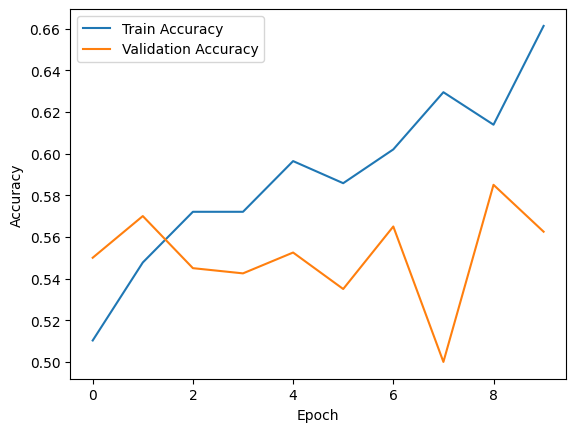

In [6]:
# Train
history = model.fit(
    train_generator,
    epochs=10,
    validation_data=validation_generator,
batch_size=32)

# Plot
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


## Step 5: Evaluate and Test

Explanation: Evaluate on validation and predict on a single image.


In [12]:
# Evaluate
val_loss, val_acc = model.evaluate(validation_generator)
print(f"Validation Accuracy: {val_acc * 100:.2f}%")

# Predict on single image
from tensorflow.keras.preprocessing import image

img_path = '/content/drive/MyDrive/Cats and Dogs Classification Dataset/Cat/832.jpg'  # Updated this!
img = image.load_img(img_path, target_size=(128, 128))
img_array = image.img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)
print("Prediction (0=Cat, 1=Dog):", "Dog" if prediction[0][0] > 0.5 else "Cat")


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.5625 - loss: 0.7587
Validation Accuracy: 56.25%
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Prediction (0=Cat, 1=Dog): Dog
